# Quantas pessoas votaram graças à prorrogação do STF?

Em 25/10/2026, às 16h22, a campanha de Lula pediu ao STF que estendesse a votação do segundo turno. O ministro Cristiano Zanin foi sorteado relator às 16h33 e às 17h03 prorrogou a votação até as 19h de Brasília (Reclamação 101.673). Em seguida a decisão foi esclarecida: valia só para as seções ainda abertas. Muitos mesários não receberam o aviso a tempo e fecharam a urna às 17h; o presidente do TRE-SP disse que 80% das seções paulistas já estavam encerradas. O TSE mandou as seções abertas aguardarem até as 19h e suspendeu a divulgação dos resultados.

Fontes: [Poder360](https://www.poder360.com.br/poder-eleicoes-2026/zanin-prorroga-votacao-do-2o-turno-ate-19h/), [Forbes](https://forbes.com.br/geral/2026/10/stf-estende-votacao-do-segundo-turno-ate-as-19h-em-todas-as-secoes/), [Exame](https://exame.com/brasil/o-horario-da-votacao-sera-estendido/), [A Gazeta](https://www.agazeta.com.br/brasil/stf-prorroga-votacao-no-segundo-turno-ate-as-19h-em-todo-o-pais-1026), [Mixvale](https://www.mixvale.com.br/2026/10/25/votacao-do-2o-turno-e-prorrogada-pelo-stf-ate-19h-mas-escolas-fecham-por-falta-de-aviso/).

As perguntas:

1. **Quantas pessoas votaram depois das 17h** no segundo turno, e quanto isso foge do normal?
2. **Quantas seções ficaram de fato abertas** até as 19h, e onde?
3. **Quanto isso pesou na vitória de Lula**, que venceu por 4,43 milhões de votos?

**Dados.** O boletim de urna do segundo turno ainda não foi publicado, e ele só traria a hora em que a urna fechou. O que responde à pergunta é o **log da urna**: cada voto gera a linha "O voto do eleitor foi computado", com o horário. Os logs completos passam de 80 GB, então `src/amostra_logs_urna.py` sorteia uma amostra estratificada por UF de 6.230 seções e baixa, do portal de resultados do TSE, o log da mesma seção nos dois turnos. O primeiro turno é a linha de base: votação até as 17h, sem prorrogação, e depois das 17h só vota quem já estava na fila. Os horários são convertidos para o de Brasília (a votação abre às 8h de Brasília em todo o país). O exterior (ZZ) fica de fora.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.options.display.float_format = "{:,.3f}".format
PROC = Path("../data/processed")
LULA, FLAVIO, CINZA, T1 = "#2a78d6", "#eb6834", "#8a8984", "#9ec5f4"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c2",
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "font.size": 10, "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})
CHAVE = ["uf", "cd_tse", "zona", "secao"]
INICIO, PASSO = 16 * 60, 5   # faixas de 5 minutos a partir das 16h de Brasília

a = pd.read_csv(PROC / "amostra_logs_urna.csv")
N = pd.read_csv(PROC / "amostra_logs_urna_estratos.csv").set_index("uf").secoes
print(a.groupby("turno").ok.agg(sorteadas="size", com_log="sum").to_string())

       sorteadas  com_log
turno                    
1           6230     6012
2           6230     6012


### Seções sem log

Cerca de 3,5% das seções sorteadas não têm arquivo no portal. São seções agregadas: os eleitores delas votam na urna de outra seção, que traz os votos das duas. Elas entram na conta com zero votos, para que a expansão para o país não conte esses eleitores duas vezes.

Cada seção pesa `N_UF / n_UF` (seções da UF sobre seções sorteadas na UF). O intervalo de 95% usa a variância do estimador estratificado, com correção de população finita.

In [2]:
FAIXAS = np.vstack(a.faixas.fillna(" ".join(["0"] * 42)).str.split().map(lambda x: np.array(x, int)))

def depois_de(h, m=0):
    i = (h * 60 + m - INICIO) // PASSO
    return FAIXAS[:, i:].sum(1)

a["votos"] = a.votos.fillna(0)
for nome, (h, m) in {"pos_17h": (17, 0), "pos_17h05": (17, 5), "pos_17h15": (17, 15),
                     "pos_17h30": (17, 30), "pos_18h": (18, 0), "pos_19h": (19, 0)}.items():
    a[nome] = depois_de(h, m)

# uma linha por seção, colunas por turno
w = a.pivot_table(index=CHAVE, columns="turno",
                  values=["votos", "pos_17h", "pos_17h05", "pos_17h15", "pos_17h30", "pos_18h", "pos_19h"],
                  aggfunc="sum")
w.columns = [f"{c}_{t}" for c, t in w.columns]
w = w.reset_index()
n = w.groupby("uf").size()
w["peso"] = w.uf.map(N / n)

def total(col, dados=w):
    tot = (dados[col] * dados.peso).sum()
    var = sum(N[u] ** 2 * (1 - len(g) / N[u]) * g[col].var() / len(g) for u, g in dados.groupby("uf"))
    return tot, 1.96 * np.sqrt(var)

oficial = pd.read_csv(PROC / "presidente_municipio_2026.csv", dtype={"cd_tse": int})
oficial = oficial[oficial.uf != "ZZ"]
for t in (1, 2):
    tot, ic = total(f"votos_{t}")
    of = oficial[oficial.turno == t].comparecimento.sum()
    print(f"{t}º turno: estimativa {tot:,.0f} ± {ic:,.0f} votantes | oficial (sem exterior) {of:,.0f} | dif {tot / of - 1:+.2%}")

1º turno: estimativa 124,948,573 ± 842,474 votantes | oficial (sem exterior) 124,934,069 | dif +0.01%
2º turno: estimativa 127,834,741 ± 873,196 votantes | oficial (sem exterior) 127,854,631 | dif -0.02%


### Validação do parser

No primeiro turno dá para comparar seção a seção o log com o boletim de urna: número de votos no log contra comparecimento, e o encerramento registrado no log contra o horário de encerramento do boletim.

In [3]:
b = pd.read_csv(PROC / "secao_presidente_1t.csv",
                usecols=["SG_UF", "CD_MUNICIPIO", "NR_ZONA", "NR_SECAO", "QT_COMPARECIMENTO", "encerramento_bsb"])
b.columns = CHAVE + ["comparecimento", "enc_bweb"]
v = a[(a.turno == 1) & a.ok].merge(b, on=CHAVE)
dif_enc = (pd.to_timedelta(v.encerramento_bsb) - pd.to_timedelta(pd.to_datetime(v.enc_bweb).dt.strftime("%H:%M:%S")))
print(f"seções comparadas: {len(v):,}")
print(f"votos no log = comparecimento do boletim: {(v.votos == v.comparecimento).mean():.1%}")
print(f"encerramento no log a até 1 min do boletim: {(dif_enc.abs() <= pd.Timedelta(minutes=1)).mean():.1%}")

seções comparadas: 6,012
votos no log = comparecimento do boletim: 99.5%
encerramento no log a até 1 min do boletim: 100.0%


## 1. Quando as pessoas votaram

A curva abaixo é o número estimado de votos no país a cada 5 minutos, das 16h às 19h30 de Brasília, nos dois turnos.

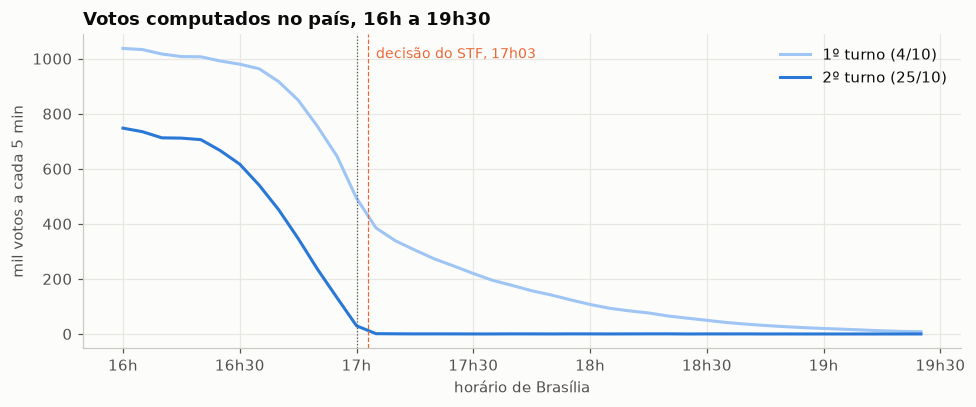

In [4]:
curva = {}
for t in (1, 2):
    m = (a.turno == t).values
    pesos = a.loc[m, "uf"].map(N / n).values
    curva[t] = (FAIXAS[m] * pesos[:, None]).sum(0)
x = INICIO + PASSO * np.arange(FAIXAS.shape[1])

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(x, curva[1] / 1e3, color=T1, lw=2, label="1º turno (4/10)")
ax.plot(x, curva[2] / 1e3, color=LULA, lw=2, label="2º turno (25/10)")
ax.axvline(17 * 60, color="#52514e", lw=0.8, ls=":")
ax.axvline(17 * 60 + 3, color=FLAVIO, lw=0.8, ls="--")
ax.text(17 * 60 + 5, ax.get_ylim()[1] * 0.92, "decisão do STF, 17h03", color=FLAVIO, fontsize=9)
ax.set_xticks(range(16 * 60, 19 * 60 + 31, 30), ["16h", "16h30", "17h", "17h30", "18h", "18h30", "19h", "19h30"])
ax.set_ylabel("mil votos a cada 5 min"); ax.set_xlabel("horário de Brasília")
ax.set_title("Votos computados no país, 16h a 19h30"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

**Leitura.** Os dois dias terminam de jeitos muito diferentes. No primeiro turno havia fila às 17h: a curva cai devagar e ainda entram cerca de 3,8 milhões de votos depois das 17h, alguns já depois das 19h. No segundo turno a curva começa a cair por volta das 16h20 e chega a quase zero às 17h. Quando a decisão saiu, às 17h03, praticamente não havia mais ninguém na fila.

Uma explicação provável, mas não testada aqui, é o tamanho da cédula: no primeiro turno o eleitor vota em seis cargos, no segundo em dois (presidente e, em parte dos estados, governador). Cada voto leva menos tempo, e a fila esvazia antes.

In [5]:
linhas = {"depois de 17h": "pos_17h", "depois de 17h05": "pos_17h05", "depois de 17h15": "pos_17h15",
          "depois de 17h30": "pos_17h30", "depois de 18h": "pos_18h", "depois de 19h": "pos_19h"}
tab = {}
for rot, col in linhas.items():
    r = {}
    for t in (1, 2):
        tot, ic = total(f"{col}_{t}")
        r[(f"{t}º turno", "votos")] = tot
        r[(f"{t}º turno", "± IC 95%")] = ic
        r[(f"{t}º turno", "% das seções")] = (w[f"{col}_{t}"] > 0).mean()
    tab[rot] = r
tab = pd.DataFrame(tab).T
tab.columns = pd.MultiIndex.from_tuples(tab.columns)
display(tab.style.format("{:,.0f}").format("{:.2%}", subset=[c for c in tab.columns if c[1] == "% das seções"]))

**Leitura.** Cerca de **35 mil pessoas** votaram depois das 17h no segundo turno, contra 3,8 milhões no primeiro. A maior parte delas votou nos primeiros cinco minutos, antes de a decisão sair ou antes de ela chegar à seção, e estava na fila às 17h, como em qualquer eleição. Depois das 17h05 votaram **cerca de 6 mil pessoas** (intervalo de 4 a 8 mil), e depois das 17h30, cerca de 3 mil.

Essas 6 mil são o teto razoável de "quem votou graças à prorrogação". Nem todas dependeram dela: parte estava na fila às 17h e votaria de qualquer jeito. No primeiro turno, sem prorrogação, 3,3 milhões votaram depois das 17h05.

## 2. As seções que ficaram abertas

O log registra também a hora em que o mesário confirmou o encerramento da urna. Uma seção que fechou depois de 18h45 de Brasília é uma seção que cumpriu a prorrogação.

In [6]:
s2 = a[(a.turno == 2) & a.ok].copy()
s2["enc_h"] = pd.to_timedelta(s2.encerramento_bsb).dt.total_seconds() / 3600
s2["aberta"] = s2.enc_h > 18.75
s2["peso"] = s2.uf.map(N / n)
print(f"seções da amostra abertas até ~19h: {s2.aberta.sum()} de {len(s2):,} ({s2.aberta.mean():.2%})")
print(f"estimativa no país: {(s2.peso * s2.aberta).sum():,.0f} seções")
por_uf = (s2.groupby("uf").agg(amostra=("aberta", "size"), abertas=("aberta", "sum"), pct=("aberta", "mean"))
          .query("abertas > 0").sort_values("pct", ascending=False))
por_uf["seções no país"] = (por_uf.pct * N[por_uf.index]).round(-1)
display(por_uf.style.format({"pct": "{:.1%}", "seções no país": "{:,.0f}"}))

seções da amostra abertas até ~19h: 78 de 6,012 (1.30%)
estimativa no país: 6,686 seções


,amostra,abertas,pct,seções no país
uf,,,,
RJ,442,39,8.8%,"3,420"
PB,126,5,4.0%,430
BA,418,12,2.9%,"1,090"
PE,248,6,2.4%,530
SP,1206,16,1.3%,"1,380"


Seções abertas até ~19h, votos depois das 17h05:
  total na amostra: 48 em 78 seções; média 0.62 por seção
  seções sem nenhum voto depois das 17h05: 54%
  estimativa no país: 4,114 votos


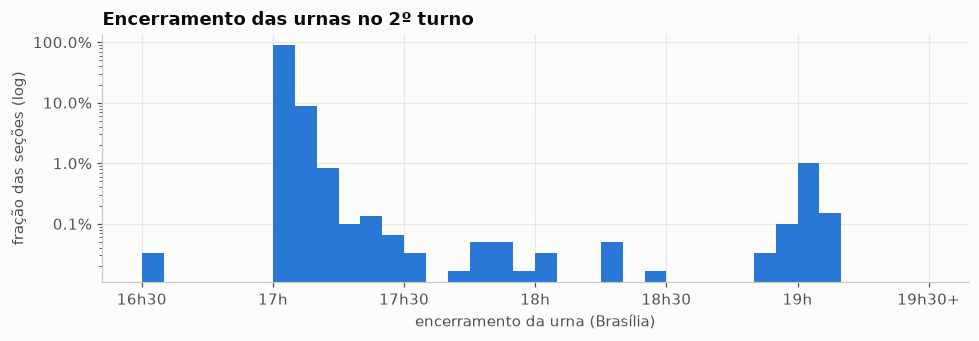

In [7]:
ab = s2[s2.aberta]
fz = a[a.turno == 2].set_index(CHAVE)
print("Seções abertas até ~19h, votos depois das 17h05:")
print(f"  total na amostra: {ab.pos_17h05.sum():.0f} em {len(ab)} seções; média {ab.pos_17h05.mean():.2f} por seção")
print(f"  seções sem nenhum voto depois das 17h05: {(ab.pos_17h05 == 0).mean():.0%}")
print(f"  estimativa no país: {(ab.pos_17h05 * ab.peso).sum():,.0f} votos")
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(s2.enc_h.clip(16.5, 19.5), bins=np.arange(16.5, 19.51, 1 / 12), color=LULA,
        weights=np.full(len(s2), 1 / len(s2)))
ax.set_yscale("log")
ax.set_xticks(np.arange(16.5, 19.51, 0.5), ["16h30", "17h", "17h30", "18h", "18h30", "19h", "19h30+"])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_ylabel("fração das seções (log)"); ax.set_xlabel("encerramento da urna (Brasília)")
ax.set_title("Encerramento das urnas no 2º turno")
plt.tight_layout(); plt.show()

**Leitura.** Cerca de 1,3% das seções, **perto de 6.700 no país**, ficaram abertas até as 19h. Elas se concentram no RJ (quase 9% das seções do estado), e aparecem também na PB, BA, PE e SP. Nos outros 22 estados a amostra não tem nenhuma seção aberta até as 19h: os mesários fecharam às 17h, como os relatos do dia indicam.

Mesmo onde a urna ficou aberta, quase ninguém apareceu: menos de um voto por seção depois das 17h05, e mais da metade dessas seções não recebeu nenhum. Duas horas a mais de urna aberta renderam cerca de 4 mil votos no país.

## 3. Quanto pesou para Lula

O log não diz em quem cada eleitor votou. Para estimar a margem que veio dos votos tardios, atribuo a cada voto tardio o resultado do segundo turno no município da seção (share de válidos sobre comparecimento e saldo Lula − Flávio sobre válidos). É uma aproximação: quem vota no fim do dia pode ser diferente de quem vota de manhã, por isso o teto ao lado supõe o pior caso, todos os votos tardios para Lula.

In [8]:
mun = oficial[oficial.turno == 2].assign(
    saldo=lambda d: (d.c13 - d.c22) / d.comparecimento)[["uf", "cd_tse", "saldo"]]
w2 = w.merge(mun, on=["uf", "cd_tse"], how="left")
print("seções sem município casado:", w2.saldo.isna().sum())
margem = (oficial[oficial.turno == 2].c13.sum() - oficial[oficial.turno == 2].c22.sum())
z = oficial[oficial.turno == 2]
print(f"margem oficial de Lula (sem exterior): {margem:,.0f}\n")
res = {}
for rot, col in {"depois de 17h": "pos_17h_2", "depois de 17h05": "pos_17h05_2", "depois de 17h15": "pos_17h15_2"}.items():
    w2["_saldo"] = w2[col] * w2.saldo.fillna(0)
    sal, ic_s = total("_saldo", w2)
    vot, ic_v = total(col, w2)
    res[rot] = {"votos": vot, "saldo estimado para Lula": sal, "± IC 95%": ic_s,
                "teto (todos para Lula)": vot + ic_v, "% da margem (teto)": (vot + ic_v) / margem}
res = pd.DataFrame(res).T
display(res.style.format({c: "{:,.0f}" for c in res.columns if c != "% da margem (teto)"} | {"% da margem (teto)": "{:.2%}"}))

seções sem município casado: 0
margem oficial de Lula (sem exterior): 4,401,534



,votos,saldo estimado para Lula,± IC 95%,teto (todos para Lula),% da margem (teto)
depois de 17h,"35,533","2,339","1,151","39,611",0.90%
depois de 17h05,"5,914",918,590,"7,703",0.18%
depois de 17h15,"4,200",483,255,"5,631",0.13%


**Leitura.** Com o resultado do município aplicado aos votos tardios, os votos depois das 17h05 deram a Lula um saldo de **cerca de 900 votos** (intervalo de 300 a 1.500). A margem dele foi de 4,40 milhões no país, sem contar o exterior (4,43 milhões com ele).

O teto vale mais do que a estimativa, porque não depende de como os eleitores tardios votaram. Mesmo que todos os votos depois das 17h05 fossem para Lula, seriam no máximo 7,7 mil, ou 0,18% da margem. Contando todos os votos depois das 17h, inclusive os da fila normal, o teto é 40 mil, 0,9% da margem.

## 4. Conclusões

1. **Quase ninguém votou graças à prorrogação.** Depois das 17h05, quando a decisão já tinha saído, votaram cerca de 6 mil pessoas no país (4 a 8 mil), 0,005% dos votantes.
2. **Não havia fila às 17h.** No segundo turno, a votação já tinha praticamente acabado quando a urna fechou. No primeiro turno, sem prorrogação, 3,8 milhões votaram depois das 17h.
3. **Poucas seções cumpriram a prorrogação**, cerca de 6.700 (1,3%), a maioria no RJ, e elas receberam em média menos de um eleitor nas duas horas extras.
4. **A prorrogação não mudou a eleição.** O saldo estimado para Lula foi de cerca de 900 votos. Mesmo no pior caso, com todo voto tardio para Lula, é 0,2% da margem de 4,4 milhões.

**Limites.** É uma amostra de 6.230 seções, com o intervalo de confiança mostrado em cada número. O log não diz em quem cada pessoa votou, então o saldo de Lula usa o resultado do município, e por isso o teto é o número mais seguro. A conta mede quem votou depois das 17h, não quem deixou de votar por achar que a seção estava fechada. O exterior não entra.